# 05 · Evaluation, Ablation Study and Report Numbers

This notebook produces every number and table for the report's **Self-evaluation** section:

1. **Ablation study**: start from a plain IoU tracker and add one component at a time, to show what each part contributes
2. **Detector effect**: the full tracker with the COCO detector vs our fine-tuned one
3. **Parameter study**: how sensitive the tracker is to its two most important settings
4. **Per-person analysis**: how many real people were tracked perfectly with a single ID
5. All tables exported as CSV + LaTeX, ready to paste into Overleaf

Everything runs on the cached detections from notebook 04, so the experiments take seconds. Only section 2 uses the GPU (about 3 minutes).

In [1]:
# ---- Setup (identical in every notebook) -----------------------------------
# The ONLY line you may need to change: where the project folder sits on your Drive.
# If a teammate shared the folder with you, right-click it in Drive ->
# "Organize" -> "Add shortcut" -> My Drive, and this path will work unchanged.
PROJECT_DIR = "/content/drive/MyDrive/DL_Project_MOT"

from google.colab import drive
drive.mount("/content/drive")

import os, sys
assert os.path.isdir(os.path.join(PROJECT_DIR, "src")), (
    f"Can't find {PROJECT_DIR}/src. Upload the project folder to Drive first (see README).")
sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))

import config
paths = config.get_paths(PROJECT_DIR)

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (switch the runtime to T4 GPU!)")

Mounted at /content/drive
Device: Tesla T4


In [2]:
import json, pickle
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mot_data import prepare_mot16, parse_gt, parse_ignore_regions
from tracker import TrackerConfig, run_tracker
from metrics import evaluate_tracking
from boxes import iou_matrix

MOT_ROOT = prepare_mot16(paths)
val_dir = f"{MOT_ROOT}/train/{config.VAL_SEQ}"
val_gt, val_ignore = parse_gt(val_dir), parse_ignore_regions(val_dir)

with open(f"{paths.detections}/{config.VAL_SEQ}_finetuned.pkl", "rb") as fh:
    val_data = pickle.load(fh)

final_run = json.load(open(f"{paths.tables}/final_run.json"))
BASE = TrackerConfig(**final_run["tracker_config"])     # exactly the settings used for the final video
COLS = ["MOTA", "IDF1", "IDSW", "MT", "ML", "FP", "FN", "pred_IDs"]

from mot_data import read_seqinfo
_vi = read_seqinfo(val_dir)
VAL_SIZE = (_vi["width"], _vi["height"])    # needed for the "left the picture" rule

def evaluate(cfg, data=val_data):
    tracks = run_tracker(data["dets"], data["feats"] if cfg.use_appearance else None, cfg, image_size=VAL_SIZE)
    return evaluate_tracking(val_gt, tracks, val_ignore)

Unzipping MOT16.zip to /content/MOT16 ...
MOT16 ready at /content/MOT16


## 1. Ablation study (MOT16-09)

| Step | What changes |
|---|---|
| A | IoU matching only, box stays where it was last seen (simplest possible tracker) |
| B | + Kalman filter motion prediction |
| C | + Siamese Re-ID appearance matching (with motion gating) |
| D | + second pass on boxes with score 0.6–0.7 (keeps partly hidden people alive) |
| E | + offline post-processing: split tracks where a person left the picture, fill drop-outs of ≤5 frames = **our full system** |

In [3]:
OFF = dict(use_low_score=False, interpolate=False, split_at_exits=False)
steps = [
    ("A  IoU only",                  replace(BASE, use_kalman=False, use_appearance=False, **OFF)),
    ("B  + Kalman filter",           replace(BASE, use_appearance=False, **OFF)),
    ("C  + Siamese Re-ID",           replace(BASE, **OFF)),
    ("D  + low-score 2nd pass",      replace(BASE, interpolate=False, split_at_exits=False)),
    ("E  + exit rule + gap fill (full)", BASE),
]
rows = []
for name, cfg in steps:
    m = evaluate(cfg)
    rows.append({"Configuration": name, **{k: m[k] for k in COLS}})
    print(f"{name:34s} MOTA {m['MOTA']:5.1f} | IDF1 {m['IDF1']:5.1f} | IDSW {m['IDSW']}")
ablation = pd.DataFrame(rows)
ablation.to_csv(f"{paths.tables}/ablation.csv", index=False)
ablation

A  IoU only                        MOTA  56.3 | IDF1  47.7 | IDSW 71
B  + Kalman filter                 MOTA  57.6 | IDF1  56.2 | IDSW 43
C  + Siamese Re-ID                 MOTA  57.4 | IDF1  62.2 | IDSW 34
D  + low-score 2nd pass            MOTA  56.0 | IDF1  60.2 | IDSW 38
E  + exit rule + gap fill (full)   MOTA  55.8 | IDF1  60.3 | IDSW 35


,Configuration,MOTA,IDF1,IDSW,MT,ML,FP,FN,pred_IDs
0,A IoU only,56.3,47.7,71,14,0,930,1295,42
1,B + Kalman filter,57.6,56.2,43,14,0,895,1290,37
2,C + Siamese Re-ID,57.4,62.2,34,13,0,919,1288,43
3,D + low-score 2nd pass,56.0,60.2,38,13,0,998,1275,47
4,E + exit rule + gap fill (full),55.8,60.3,35,14,0,1073,1214,49


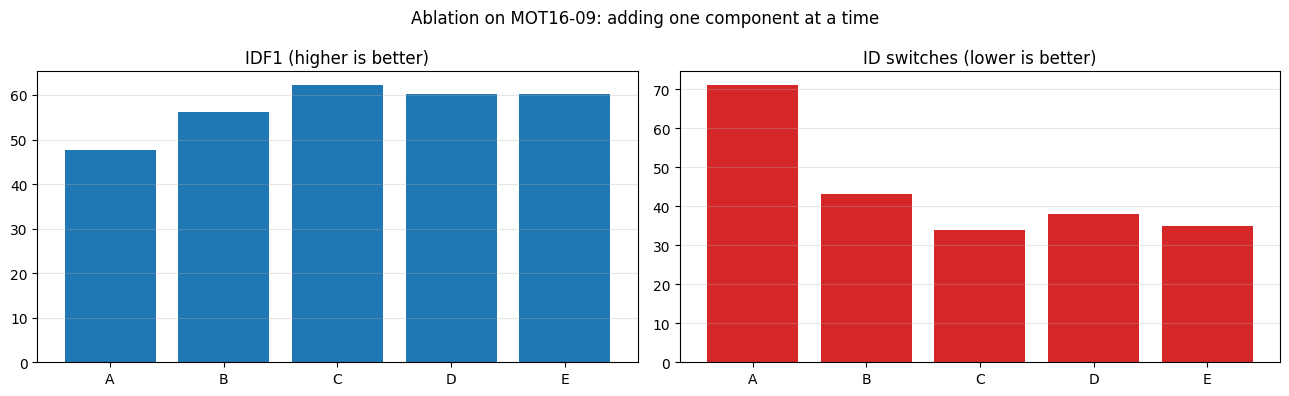

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
labels = [r.split("  ")[0] for r in ablation["Configuration"]]
ax[0].bar(labels, ablation["IDF1"], color="tab:blue"); ax[0].set_title("IDF1 (higher is better)")
ax[1].bar(labels, ablation["IDSW"], color="tab:red"); ax[1].set_title("ID switches (lower is better)")
for a in ax:
    a.grid(axis="y", alpha=.3)
plt.suptitle(f"Ablation on {config.VAL_SEQ}: adding one component at a time")
plt.tight_layout(); plt.savefig(f"{paths.figures}/ablation.png", dpi=150); plt.show()

## 2. Does fine-tuning the detector help the *tracking*?

Same full tracker, same Re-ID model; only the detector changes. (Runs the COCO detector over MOT16-09 once, about 3 minutes, then caches it.)

In [5]:
from detector import build_coco_detector
from reid import load_reid
from pipeline import process_sequence

coco_cache = f"{paths.detections}/{config.VAL_SEQ}_coco.pkl"
coco_model = build_coco_detector().to(device).eval() if not os.path.exists(coco_cache) else None
reid_model = load_reid(paths.reid_ckpt, device) if not os.path.exists(coco_cache) else None
coco_data = process_sequence(coco_model, reid_model, val_dir, device, score_thresh=0.3, cache_path=coco_cache)
del coco_model, reid_model; torch.cuda.empty_cache()

det_rows = []
for name, data in [("COCO pretrained detector", coco_data), ("Fine-tuned detector (ours)", val_data)]:
    m = evaluate(BASE, data)
    det_rows.append({"Detector (full tracker)": name, **{k: m[k] for k in COLS}})
det_table = pd.DataFrame(det_rows)
det_table.to_csv(f"{paths.tables}/tracking_by_detector.csv", index=False)
det_table

Loaded cached detections: MOT16-09_coco.pkl


,Detector (full tracker),MOTA,IDF1,IDSW,MT,ML,FP,FN,pred_IDs
0,COCO pretrained detector,51.1,54.2,37,13,0,1185,1347,68
1,Fine-tuned detector (ours),55.8,60.3,35,14,0,1073,1214,49


## 3. Parameter study

The two settings that matter most for keeping IDs:
* `max_age`: how many frames a lost person is remembered (longer = survives longer occlusions, but risks re-attaching to the wrong person)
* `app_thresh`: how similar two crops must look to be called the same person

**Honest note for the report:** MOT16-09 is also where we evaluate, so choosing settings here slightly flatters our validation numbers. We keep the grid small and coarse for that reason, and say so.

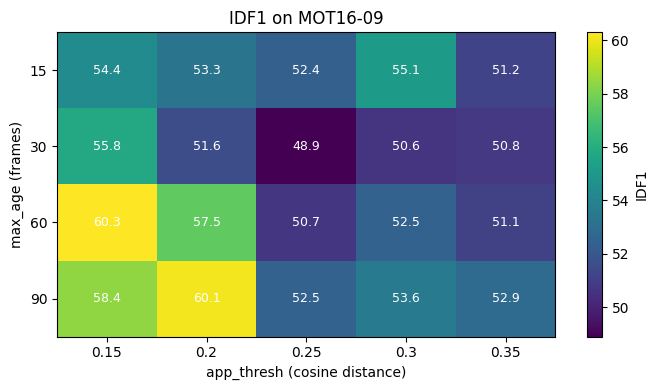

Best: max_age=60, app_thresh=0.15 -> IDF1 60.3 (final video used max_age=60, app_thresh=0.15)


In [6]:
ages = [15, 30, 60, 90]
threshs = [0.15, 0.2, 0.25, 0.3, 0.35]
grid = np.zeros((len(ages), len(threshs)))
for i, a in enumerate(ages):
    for j, t in enumerate(threshs):
        grid[i, j] = evaluate(replace(BASE, max_age=a, app_thresh=t, max_gap=BASE.max_gap))["IDF1"]

plt.figure(figsize=(7, 4))
plt.imshow(grid, cmap="viridis", aspect="auto")
plt.xticks(range(len(threshs)), threshs); plt.yticks(range(len(ages)), ages)
plt.xlabel("app_thresh (cosine distance)"); plt.ylabel("max_age (frames)")
for i in range(len(ages)):
    for j in range(len(threshs)):
        plt.text(j, i, f"{grid[i, j]:.1f}", ha="center", va="center", color="w", fontsize=9)
plt.colorbar(label="IDF1"); plt.title(f"IDF1 on {config.VAL_SEQ}")
plt.tight_layout(); plt.savefig(f"{paths.figures}/param_study.png", dpi=150); plt.show()

bi, bj = np.unravel_index(grid.argmax(), grid.shape)
print(f"Best: max_age={ages[bi]}, app_thresh={threshs[bj]} -> IDF1 {grid[bi, bj]:.1f} "
      f"(final video used max_age={BASE.max_age}, app_thresh={BASE.app_thresh})")

If the best setting here is clearly better than the one used in notebook 04, update `cfg` there (for example `cfg.max_age = 90`), re-run its sections 2–6, then re-run this notebook so all tables match the final video.

## 4. Per-person analysis: who was tracked perfectly?

For each real person in MOT16-09 we check:
* **coverage**: share of their frames where one of our boxes was on them
* **number of different IDs** we gave them

"Perfectly tracked" = covered in ≥ 90% of their frames **with a single ID**. That is the rubric's A-criterion applied to every person in a labelled video, which makes it strong evidence for the target in the test video.

People visible >= 100 frames: 18 | tracked perfectly (>=90% coverage, 1 ID): 2
Average number of IDs per person: 2.60


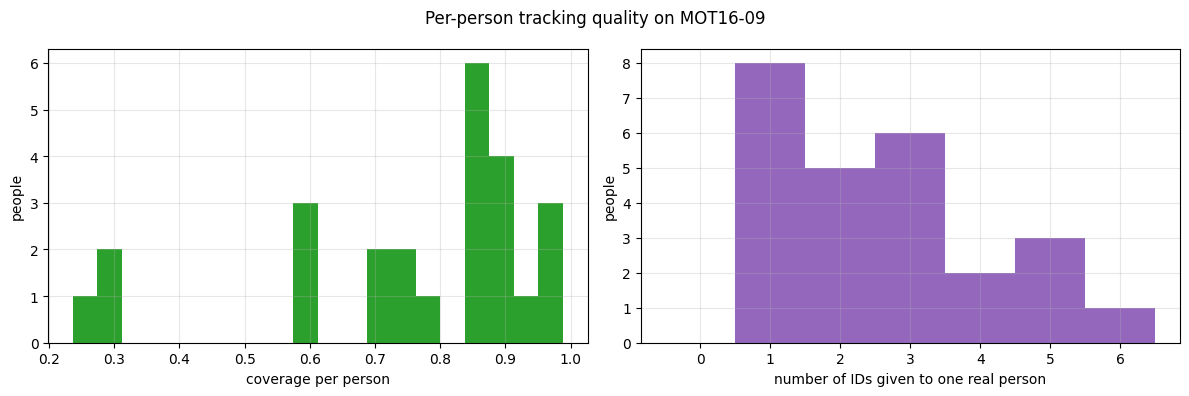

In [7]:
from scipy.optimize import linear_sum_assignment

def per_person(gt, tracks, iou_thr=0.5):
    stats = {}
    for f, g in gt.items():
        p = tracks.get(f, np.zeros((0, 6)))
        for gid in g[:, 0].astype(int):
            stats.setdefault(gid, {"frames": 0, "covered": 0, "ids": set()})["frames"] += 1
        if len(p) == 0:
            continue
        iou = iou_matrix(g[:, 1:5], p[:, 1:5])
        for r, c in zip(*linear_sum_assignment(-iou)):
            if iou[r, c] >= iou_thr:
                s = stats[int(g[r, 0])]
                s["covered"] += 1
                s["ids"].add(int(p[c, 0]))
    return pd.DataFrame([{"gt_id": k, "frames": v["frames"], "coverage": v["covered"] / v["frames"],
                          "num_ids": len(v["ids"])} for k, v in stats.items()])

full_tracks = run_tracker(val_data["dets"], val_data["feats"], BASE, image_size=VAL_SIZE)
pp = per_person(val_gt, full_tracks)
long_lived = pp[pp["frames"] >= 100]          # people visible for at least ~3 seconds
perfect = long_lived[(long_lived["coverage"] >= 0.9) & (long_lived["num_ids"] == 1)]
print(f"People visible >= 100 frames: {len(long_lived)} | tracked perfectly (>=90% coverage, 1 ID): {len(perfect)}")
print(f"Average number of IDs per person: {pp['num_ids'].mean():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(pp["coverage"], bins=20, color="tab:green"); ax[0].set_xlabel("coverage per person")
ax[1].hist(pp["num_ids"], bins=range(0, pp["num_ids"].max() + 2), color="tab:purple", align="left")
ax[1].set_xlabel("number of IDs given to one real person")
for a in ax:
    a.set_ylabel("people"); a.grid(alpha=.3)
plt.suptitle(f"Per-person tracking quality on {config.VAL_SEQ}")
plt.tight_layout(); plt.savefig(f"{paths.figures}/per_person.png", dpi=150); plt.show()
pp.to_csv(f"{paths.tables}/per_person.csv", index=False)

## 5. Export tables for the report (LaTeX)

In [8]:
def to_latex(df, path, caption, label):
    tex = df.to_latex(index=False, float_format="%.1f", caption=caption, label=label, position="h")
    open(path, "w").write(tex)
    return tex

speed = pd.read_csv(f"{paths.tables}/speed.csv")
det = pd.read_csv(f"{paths.tables}/detector_results.csv")
reid = pd.read_csv(f"{paths.tables}/reid_results.csv")

to_latex(ablation, f"{paths.tables}/ablation.tex", f"Ablation study on {config.VAL_SEQ}.", "tab:ablation")
to_latex(det_table, f"{paths.tables}/tracking_by_detector.tex", "Effect of detector fine-tuning on tracking.", "tab:detector_tracking")
to_latex(speed, f"{paths.tables}/speed.tex", "Runtime per stage on a Colab T4 GPU.", "tab:speed")
open(f"{paths.tables}/detector.tex", "w").write(det.to_latex(index=False, float_format="%.3f",
     caption="Detection results on MOT16-09.", label="tab:detector", position="h"))
open(f"{paths.tables}/reid.tex", "w").write(reid.to_latex(index=False, float_format="%.3f",
     caption="Re-ID results on unseen identities (MOT16-09).", label="tab:reid", position="h"))
print("LaTeX tables written to", paths.tables)

LaTeX tables written to /content/drive/MyDrive/DL_Project_MOT/results/tables


In [9]:
# Every headline number in one place, for the abstract and the slides
full = ablation.iloc[-1]
base = ablation.iloc[0]
print(f"""
=== Numbers for the report ===
Detector AP@0.5 on {config.VAL_SEQ}:  COCO {det.iloc[0]['AP@0.5']:.3f}  ->  fine-tuned {det.iloc[1]['AP@0.5']:.3f}
Re-ID rank-1 (unseen people):     ImageNet {reid.iloc[0]['Rank-1']:.3f}  ->  ours {reid.iloc[1]['Rank-1']:.3f}
Tracking on {config.VAL_SEQ}:  IDF1 {base['IDF1']:.1f} -> {full['IDF1']:.1f} | IDSW {base['IDSW']} -> {full['IDSW']} | MOTA {base['MOTA']:.1f} -> {full['MOTA']:.1f}
Perfectly tracked long-lived people: {len(perfect)} / {len(long_lived)}
Total speed: {speed.iloc[-1]['FPS']:.1f} FPS on {final_run['gpu']}
Final target in {config.TEST_SEQ}: ID {final_run['target_id']}
""")


=== Numbers for the report ===
Detector AP@0.5 on MOT16-09:  COCO 0.741  ->  fine-tuned 0.780
Re-ID rank-1 (unseen people):     ImageNet 0.812  ->  ours 0.914
Tracking on MOT16-09:  IDF1 47.7 -> 60.3 | IDSW 71 -> 35 | MOTA 56.3 -> 55.8
Perfectly tracked long-lived people: 2 / 18
Total speed: 8.6 FPS on Tesla T4
Final target in MOT16-01: ID 11



## Done ✅

Everything for the report is now in `results/`:
* `tables/*.csv` and `tables/*.tex` (paste the `.tex` files straight into Overleaf)
* `figures/*.png|jpg`
* `tracks/*.txt` in the official MOTChallenge format

These are small files, so they go to GitHub with the code.